In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [110]:
df = pd.read_csv('datasets/Startups.csv')
states = df['State'].unique()
df['State'] = df['State'].map({state: i for i, state in enumerate(states)})

df = df.drop_duplicates()
df = df.dropna()

train = df.sample(frac=0.8, random_state=4242)
test = df.drop(train.index)

y_train = train['Profit'].to_numpy().reshape(-1, 1)
y_test = test['Profit'].to_numpy().reshape(-1, 1)
X_train = train.drop(columns=['Profit']).to_numpy()
X_test = test.drop(['Profit'], axis=1).to_numpy()

mean = X_train.mean(axis = 0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std

X_train = np.c_[np.ones((X_train.shape[0], 1)), X_train]

In [111]:
beta = np.zeros((X_train.shape[1], 1))
eta = 0.005
epoches = 1000
losses = []

for _ in range(epoches):
    y_pred = X_train @ beta
    loss = np.mean((y_train - y_pred) ** 2)
    losses.append(loss)

    gradient = -(2 / X_train.shape[0]) * (X_train.T @ (y_train - y_pred))
    beta -= eta * gradient

losses

[np.float64(15309364386.012146),
 np.float64(14986795637.35011),
 np.float64(14671365069.96572),
 np.float64(14362904808.00497),
 np.float64(14061251239.439413),
 np.float64(13766244898.236227),
 np.float64(13477730350.05135),
 np.float64(13195556081.333488),
 np.float64(12919574391.730452),
 np.float64(12649641289.69305),
 np.float64(12385616391.175138),
 np.float64(12127362821.331787),
 np.float64(11874747119.120876),
 np.float64(11627639144.716434),
 np.float64(11385911989.645176),
 np.float64(11149441889.560593),
 np.float64(10918108139.57172),
 np.float64(10691793012.04654),
 np.float64(10470381676.812523),
 np.float64(10253762123.679441),
 np.float64(10041825087.211966),
 np.float64(9834463973.682014),
 np.float64(9631574790.133078),
 np.float64(9433056075.490955),
 np.float64(9238808833.657536),
 np.float64(9048736468.526245),
 np.float64(8862744720.859882),
 np.float64(8680741606.9734),
 np.float64(8502637359.166147),
 np.float64(8328344367.849813),
 np.float64(8157777125.32012

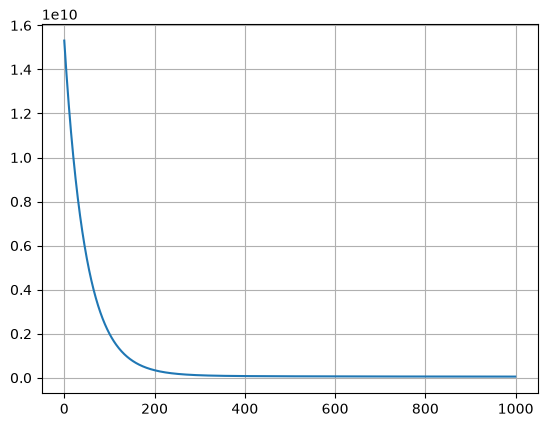

In [ ]:
plt.plot(losses)
plt.grid(True)
plt.show()